In [1]:
# Import Path to access folders and files
from pathlib import Path

# Import pandas to organize the dataset information in tables
import pandas as pd

# Import matplotlib to create charts
import matplotlib.pyplot as plt

# Import random to select sample images randomly
import random

# Import Image to open and inspect images
from PIL import Image

In [2]:
# Store the location of the extracted SDNET2018 dataset
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Check whether the dataset folder exists
print("Dataset folder exists:", DATA_DIR.exists())

Dataset folder exists: True


In [3]:
# Create an empty list to store the image counts
class_counts = []

# Go through each surface folder in the dataset
for surface_folder in sorted(DATA_DIR.iterdir()):

    # Skip hidden folders and files
    if surface_folder.name.startswith(".") or not surface_folder.is_dir():
        continue

    # Go through each class folder inside the surface folder
    for class_folder in sorted(surface_folder.iterdir()):

        # Skip anything that is not a folder
        if not class_folder.is_dir():
            continue

        # Count the JPG images in the current class folder
        image_count = len(list(class_folder.glob("*.jpg")))

        # Identify the surface type using the folder name
        if surface_folder.name == "D":
            surface = "Decks"
        elif surface_folder.name == "P":
            surface = "Pavements"
        else:
            surface = "Walls"

        # Identify whether the images are cracked or uncracked
        if class_folder.name.startswith("C"):
            image_class = "Cracked"
        else:
            image_class = "Uncracked"

        # Save the surface, class and count in the list
        class_counts.append({
            "Surface": surface,
            "Class": image_class,
            "Count": image_count
        })

# Convert the list into a pandas DataFrame
class_df = pd.DataFrame(class_counts)

# Display the image counts in a table
display(class_df)

# Calculate and display the total number of images
print("Total images:", class_df["Count"].sum())

,Surface,Class,Count
0,Decks,Cracked,2025
1,Decks,Uncracked,11595
2,Pavements,Cracked,2608
3,Pavements,Uncracked,21726
4,Walls,Cracked,3851
5,Walls,Uncracked,14287


Total images: 56092


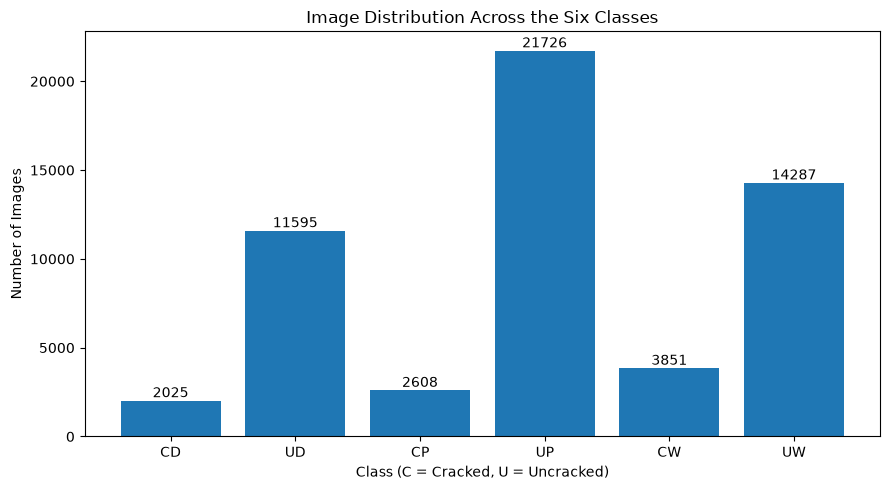

In [4]:
# Create a bar chart showing the number of images in each class
plt.figure(figsize=(9, 5))

# Draw the bars using the class folder names and image counts
plt.bar(
    ["CD", "UD", "CP", "UP", "CW", "UW"],
    [2025, 11595, 2608, 21726, 3851, 14287]
)

# Add a title to the chart
plt.title("Image Distribution Across the Six Classes")

# Label the horizontal axis
plt.xlabel("Class (C = Cracked, U = Uncracked)")

# Label the vertical axis
plt.ylabel("Number of Images")

# Display the exact count above each bar
plt.bar_label(plt.gca().containers[0])

# Adjust the layout so the labels fit
plt.tight_layout()

# Display the chart
plt.show()

In [5]:
# Add the counts of cracked and uncracked images
class_summary = class_df.groupby("Class")["Count"].sum()

# Calculate the total number of images
total_images = class_summary.sum()

# Calculate the percentage of cracked images
cracked_percentage = (class_summary["Cracked"] / total_images) * 100

# Calculate the percentage of uncracked images
uncracked_percentage = (class_summary["Uncracked"] / total_images) * 100

# Display the number of cracked images
print("Cracked images:", class_summary["Cracked"])

# Display the number of uncracked images
print("Uncracked images:", class_summary["Uncracked"])

# Display the percentage of cracked images
print("Cracked image percentage:", round(cracked_percentage, 2), "%")

# Display the percentage of uncracked images
print("Uncracked image percentage:", round(uncracked_percentage, 2), "%")

Cracked images: 8484
Uncracked images: 47608
Cracked image percentage: 15.13 %
Uncracked image percentage: 84.87 %


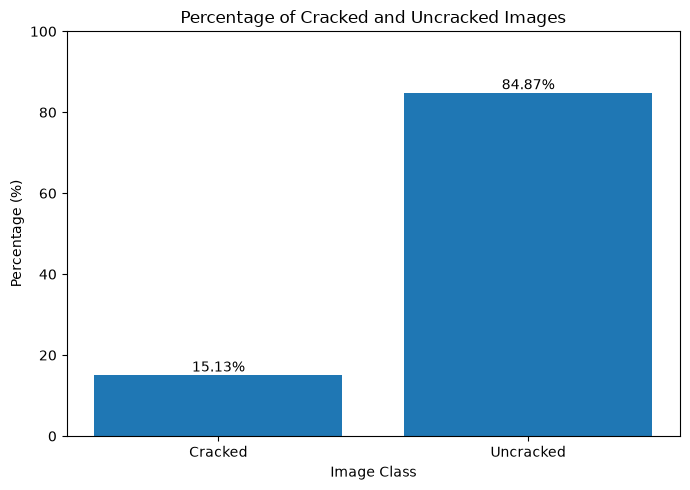

In [6]:
# Create a figure for the class distribution chart
plt.figure(figsize=(7, 5))

# Draw a bar for each class percentage
plt.bar(
    ["Cracked", "Uncracked"],
    [cracked_percentage, uncracked_percentage]
)

# Add a title to the chart
plt.title("Percentage of Cracked and Uncracked Images")

# Label the horizontal axis
plt.xlabel("Image Class")

# Label the vertical axis
plt.ylabel("Percentage (%)")

# Set the vertical axis range from 0 to 100
plt.ylim(0, 100)

# Display the percentage above each bar
plt.bar_label(plt.gca().containers[0], fmt="%.2f%%")

# Adjust spacing in the figure
plt.tight_layout()

# Display the chart
plt.show()

The dataset contains 8,484 cracked images (15.13%) and 47,608 uncracked images (84.87%). This shows a clear class imbalance, as uncracked images make up most of the dataset. This imbalance should be considered during model training and evaluation, since accuracy alone may not fully describe how well a model detects cracks.

## 4. Surface-Wise Class Distribution
This section compares the number of cracked and uncracked images across bridge decks, pavements, and walls. It helps us understand whether the class distribution is similar across different concrete surfaces.

Class,Cracked,Uncracked
Surface,,
Decks,2025,11595
Pavements,2608,21726
Walls,3851,14287


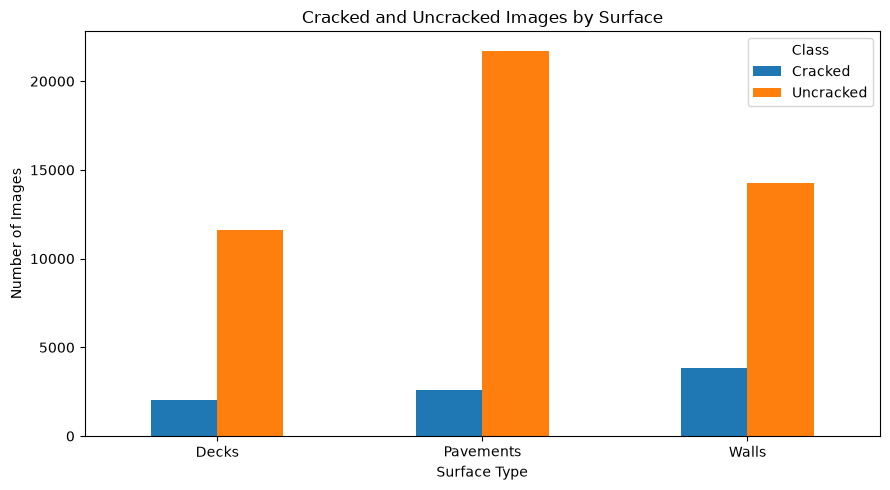

In [7]:
# Group the data by surface and class
surface_summary = class_df.pivot(
    index="Surface",
    columns="Class",
    values="Count"
)

# Display the number of cracked and uncracked images for each surface
display(surface_summary)

# Create a bar chart for the surface-wise comparison
surface_summary.plot(kind="bar", figsize=(9, 5))

# Add a title to the chart
plt.title("Cracked and Uncracked Images by Surface")

# Label the horizontal axis
plt.xlabel("Surface Type")

# Label the vertical axis
plt.ylabel("Number of Images")

# Keep the surface names horizontal
plt.xticks(rotation=0)

# Adjust the chart layout
plt.tight_layout()

# Display the chart
plt.show()

In [8]:
# Calculate the total number of images for each surface
surface_summary["Total"] = (
    surface_summary["Cracked"] + surface_summary["Uncracked"]
)

# Calculate the percentage of cracked images for each surface
surface_summary["Cracked Percentage"] = (
    surface_summary["Cracked"] / surface_summary["Total"] * 100
)

# Display the surface totals and cracked percentages
display(surface_summary.round(2))

Class,Cracked,Uncracked,Total,Cracked Percentage
Surface,,,,
Decks,2025,11595,13620,14.87
Pavements,2608,21726,24334,10.72
Walls,3851,14287,18138,21.23


### Observation

The proportion of cracked images differs across the three surface types. Walls have the highest cracked-image percentage, while pavements have the lowest. This suggests that the dataset's class distribution should be examined by surface as well as overall. These results describe the dataset composition and should not be interpreted as evidence that one surface type is more likely to develop cracks in real-world conditions.

## 5. Visual Exploration of Sample Images

This section displays sample images from the six SDNET2018 classes. Visual inspection helps us understand the appearance of cracks, variations in concrete texture, and possible differences between cracked and uncracked surfaces.

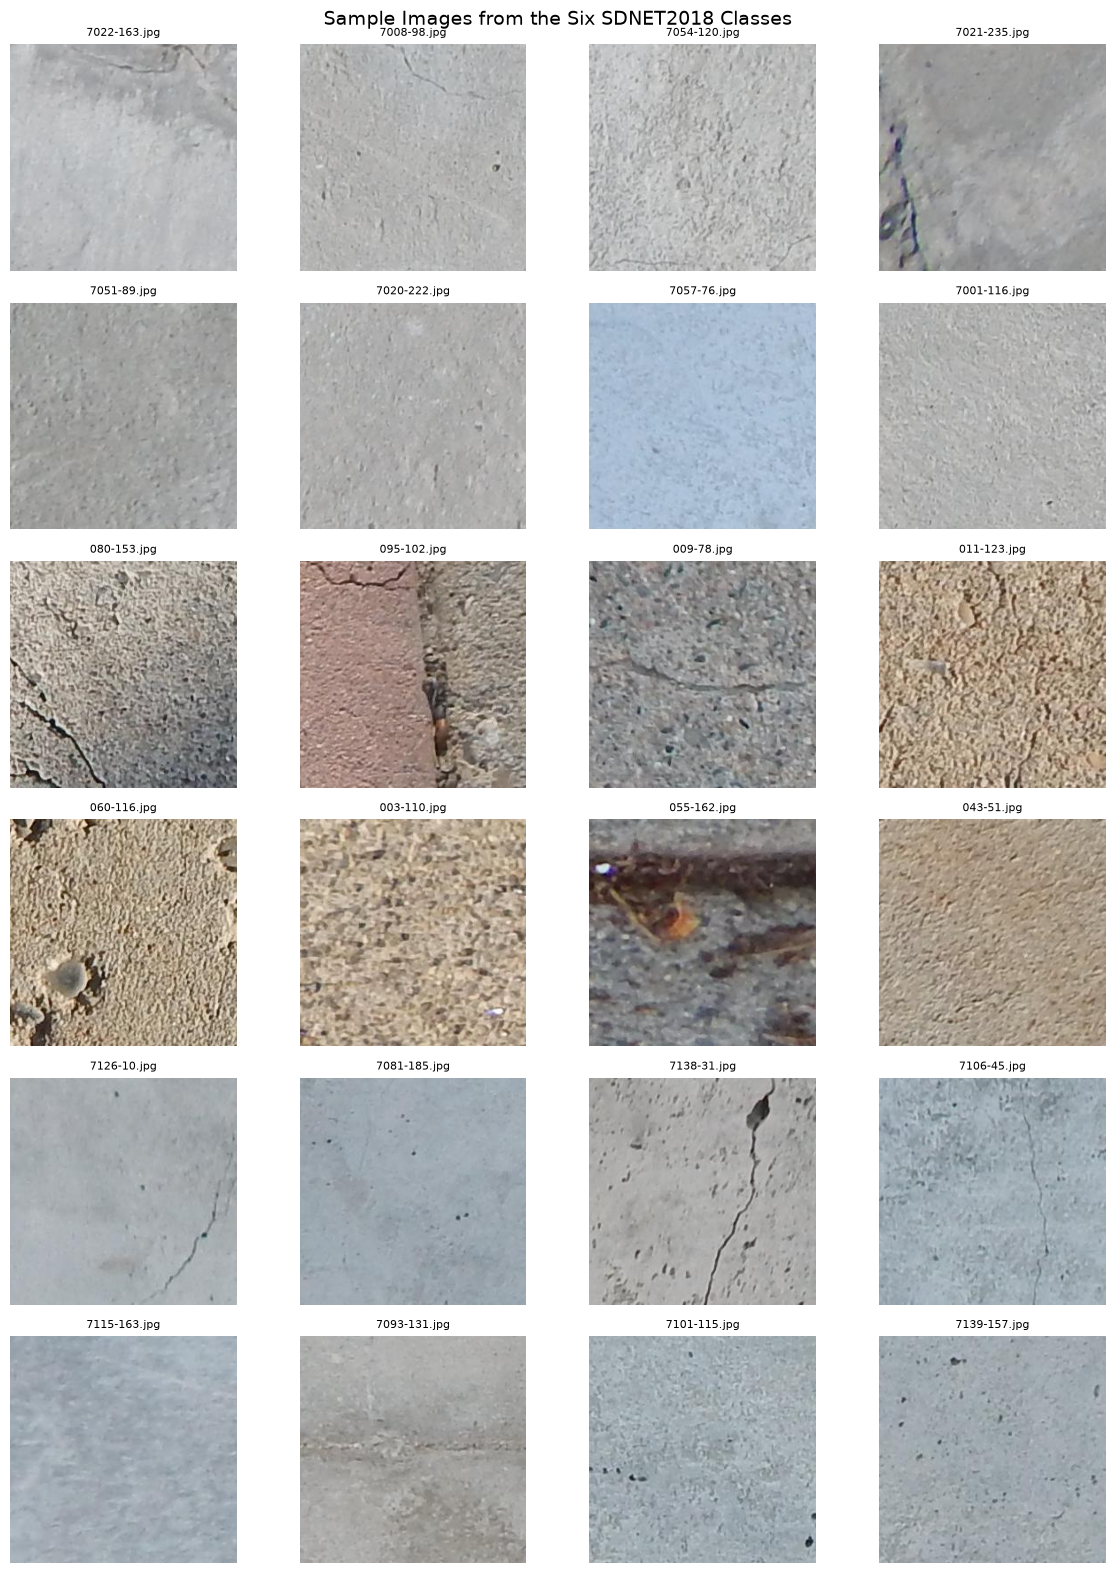

In [9]:
# randomly selects four images from each class folder and displays them in a grid.

# Import the random module to select images randomly
import random

# Import matplotlib to display the images
import matplotlib.pyplot as plt

# Import Image from PIL to open the image files
from PIL import Image

# Define the six class folders and their display names
class_folders = {
    "Cracked Decks (CD)": DATA_DIR / "D" / "CD",
    "Uncracked Decks (UD)": DATA_DIR / "D" / "UD",
    "Cracked Pavements (CP)": DATA_DIR / "P" / "CP",
    "Uncracked Pavements (UP)": DATA_DIR / "P" / "UP",
    "Cracked Walls (CW)": DATA_DIR / "W" / "CW",
    "Uncracked Walls (UW)": DATA_DIR / "W" / "UW"
}

# Set the number of images to display from each class
images_per_class = 4

# Create a figure with six rows and four columns
fig, axes = plt.subplots(6, images_per_class, figsize=(12, 16))

# Go through each class folder and its row number
for row, (class_name, folder_path) in enumerate(class_folders.items()):

    # Get all JPG image paths in the current folder
    image_paths = list(folder_path.glob("*.jpg"))

    # Randomly select four images from the folder
    selected_images = random.sample(image_paths, images_per_class)

    # Go through each selected image and its column number
    for col, image_path in enumerate(selected_images):

        # Open the selected image
        img = Image.open(image_path)

        # Display the image in the correct grid position
        axes[row, col].imshow(img)

        # Remove the axis numbers for a cleaner display
        axes[row, col].axis("off")

        # Add the image filename as a small title
        axes[row, col].set_title(image_path.name, fontsize=8)

    # Add the class name to the left of each row
    axes[row, 0].set_ylabel(class_name, fontsize=10)

# Add a title above the complete figure
plt.suptitle("Sample Images from the Six SDNET2018 Classes", fontsize=14)

# Adjust the spacing between images
plt.tight_layout()

# Display the complete figure
plt.show()

### Visual Observations

Visual inspection showed that crack visibility varies across the dataset. In several deck and wall images, it was difficult to determine visually whether a crack was present. Among the sampled images labelled as cracked, some contained clearly visible cracks, while others showed faint or ambiguous patterns. Some images labelled as uncracked also contained lines or surface marks that resembled cracks.

These observations suggest that crack detection may be challenging because of variations in crack visibility and concrete surface texture. However, the samples are not sufficient to establish whether the dataset contains incorrect labels. Further inspection of additional images is required.

## 6. Image Brightness and Contrast Analysis

This section examines the brightness and contrast of sample images from the SDNET2018 dataset. Brightness describes how light or dark an image is, while contrast describes the variation between lighter and darker pixels. These properties may affect how clearly cracks can be distinguished from the surrounding concrete surface.

In [10]:
# Import NumPy to calculate image statistics
import numpy as np

# Import random to select a sample of images
import random

# Create an empty list to store the results
image_stats = []

# Set the number of images to sample from each class
sample_size = 100

# Set a seed so we can repeat the same random sample
random.seed(42)

# Go through each class folder
for class_name, folder_path in class_folders.items():

    # Get all JPG images from the current folder
    image_paths = list(folder_path.glob("*.jpg"))

    # Select up to 100 images from the folder
    selected_images = random.sample(
        image_paths, min(sample_size, len(image_paths))
    )

    # Go through each selected image
    for image_path in selected_images:

        # Open the image and convert it to grayscale
        img = Image.open(image_path).convert("L")

        # Convert the image pixels into a NumPy array
        pixels = np.array(img)

        # Calculate the average pixel value as brightness
        brightness = np.mean(pixels)

        # Calculate the standard deviation as a simple contrast measure
        contrast = np.std(pixels)

        # Save the class name and measurements
        image_stats.append({
            "Class": class_name,
            "Brightness": brightness,
            "Contrast": contrast
        })

# Convert the results into a DataFrame
image_stats_df = pd.DataFrame(image_stats)

# Display the first five rows
display(image_stats_df.head())

# Display the number of sampled images in each class
print("Images analysed:", len(image_stats_df))

,Class,Brightness,Contrast
0,Cracked Decks (CD),177.988937,7.377539
1,Cracked Decks (CD),176.361450,11.530525
2,Cracked Decks (CD),180.454834,12.823967
3,Cracked Decks (CD),182.110519,10.773874
4,Cracked Decks (CD),185.666870,6.163685


Images analysed: 600


In [11]:
# Calculate the average brightness and contrast for each class
class_image_stats = image_stats_df.groupby("Class")[
    ["Brightness", "Contrast"]
].mean()

# Display the average measurements rounded to two decimal places
display(class_image_stats.round(2))

,Brightness,Contrast
Class,,
Cracked Decks (CD),177.00,10.35
Cracked Pavements (CP),153.25,27.76
Cracked Walls (CW),171.41,9.28
Uncracked Decks (UD),169.74,10.66
Uncracked Pavements (UP),152.12,21.58
Uncracked Walls (UW),166.72,8.87


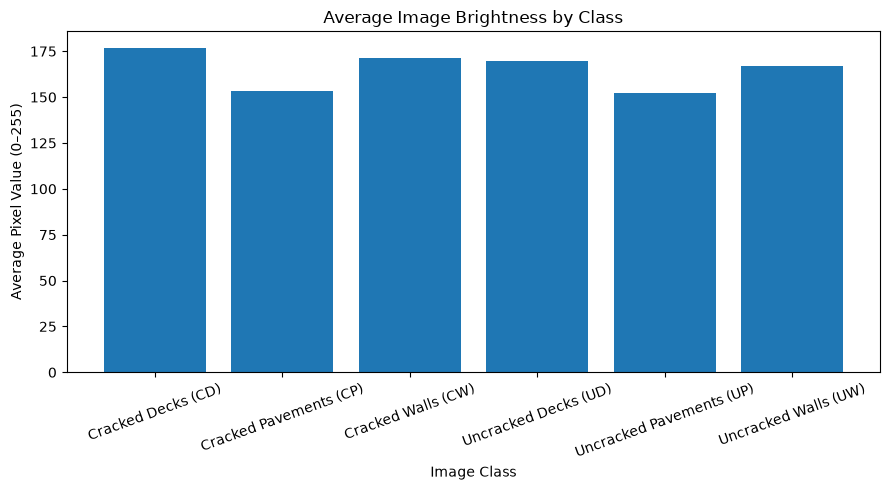

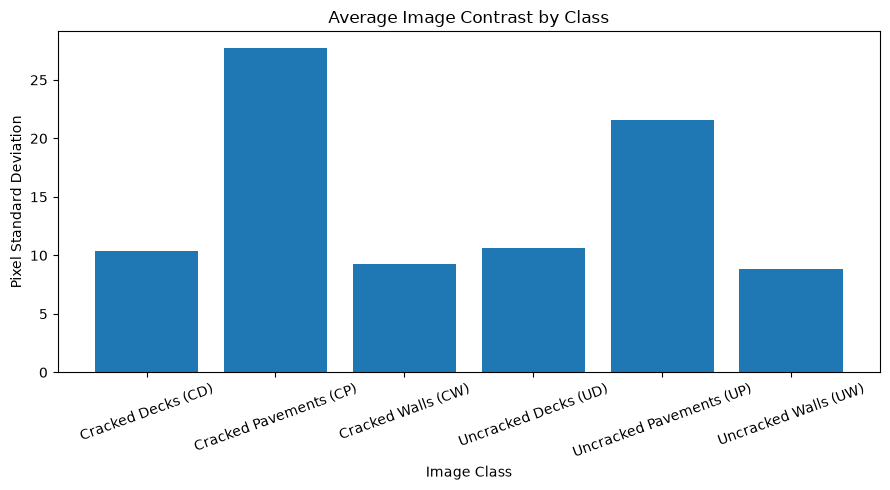

In [12]:
# Create a figure for the brightness chart
plt.figure(figsize=(9, 5))

# Plot the average brightness of each class
plt.bar(class_image_stats.index, class_image_stats["Brightness"])

# Add a title to the chart
plt.title("Average Image Brightness by Class")

# Label the horizontal axis
plt.xlabel("Image Class")

# Label the vertical axis
plt.ylabel("Average Pixel Value (0–255)")

# Rotate the class labels slightly for readability
plt.xticks(rotation=20)

# Adjust the spacing
plt.tight_layout()

# Display the chart
plt.show()


# Create a figure for the contrast chart
plt.figure(figsize=(9, 5))

# Plot the average contrast of each class
plt.bar(class_image_stats.index, class_image_stats["Contrast"])

# Add a title to the chart
plt.title("Average Image Contrast by Class")

# Label the horizontal axis
plt.xlabel("Image Class")

# Label the vertical axis
plt.ylabel("Pixel Standard Deviation")

# Rotate the class labels slightly for readability
plt.xticks(rotation=20)

# Adjust the spacing
plt.tight_layout()

# Display the chart
plt.show()

### Observation
The brightness and contrast analysis showed differences among the six classes. Pavement images had lower average brightness than deck and wall images. Cracked pavements also showed higher average contrast than uncracked pavements. In comparison, deck and wall images had lower contrast values overall.

These differences suggest that surface appearance varies across the dataset. However, average brightness and contrast alone cannot determine whether cracks are clearly visible, so the results should be considered alongside visual inspection.

## 7. Duplicate Image Check

In [13]:
# Import hashlib to calculate a unique hash for each file
import hashlib

# Import pandas to create a table of duplicate images
import pandas as pd

# Import Path to access folders and files
from pathlib import Path

# Set the location of the SDNET2018 dataset
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Import Path to access the dataset folders
from pathlib import Path

# Set the location of the SDNET2018 dataset
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Check that the dataset folder exists
print("Dataset folder exists:", DATA_DIR.exists())

# Create a dictionary to store image hashes and their file paths
image_hashes = {}

# Create a list to store duplicate image paths
duplicate_images = []

# Go through every JPG image in the dataset
for image_path in DATA_DIR.rglob("*.jpg"):

    # Open the image file in binary mode
    with open(image_path, "rb") as file:

        # Read the file contents
        file_content = file.read()

        # Calculate the SHA-256 hash of the file
        file_hash = hashlib.sha256(file_content).hexdigest()

    # Check whether this exact file content was seen before
    if file_hash in image_hashes:

        # Record the duplicate and its original file
        duplicate_images.append({
            "Duplicate Path": str(image_path),
            "Original Path": image_hashes[file_hash]
        })

    else:

        # Save the hash and path for a new image
        image_hashes[file_hash] = str(image_path)

# Display the number of duplicate files found
print("Exact duplicate images:", len(duplicate_images))

# Convert the duplicate list into a table
duplicates_df = pd.DataFrame(duplicate_images)

# Display the first few duplicates if any exist
display(duplicates_df.head(10))

Dataset folder exists: True
Exact duplicate images: 13


,Duplicate Path,Original Path
0,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
1,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
2,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
3,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
4,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
5,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
6,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
7,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
8,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
9,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...


In [14]:
# Display the complete paths of all duplicate images
pd.set_option("display.max_colwidth", None)

# Create a table showing the duplicate file paths
duplicates_df = pd.DataFrame(duplicate_images)

# Display every duplicate entry
display(duplicates_df)

,Duplicate Path,Original Path
0,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-110_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-110.jpg
1,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-111_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-111.jpg
2,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-113_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-113.jpg
3,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7039-112_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039-112.jpg
4,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-17_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-17.jpg
5,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-18_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-18.jpg
6,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-35_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-35.jpg
7,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-36_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-36.jpg
8,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-53_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-53.jpg
9,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-54_2.jpg,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053-54.jpg


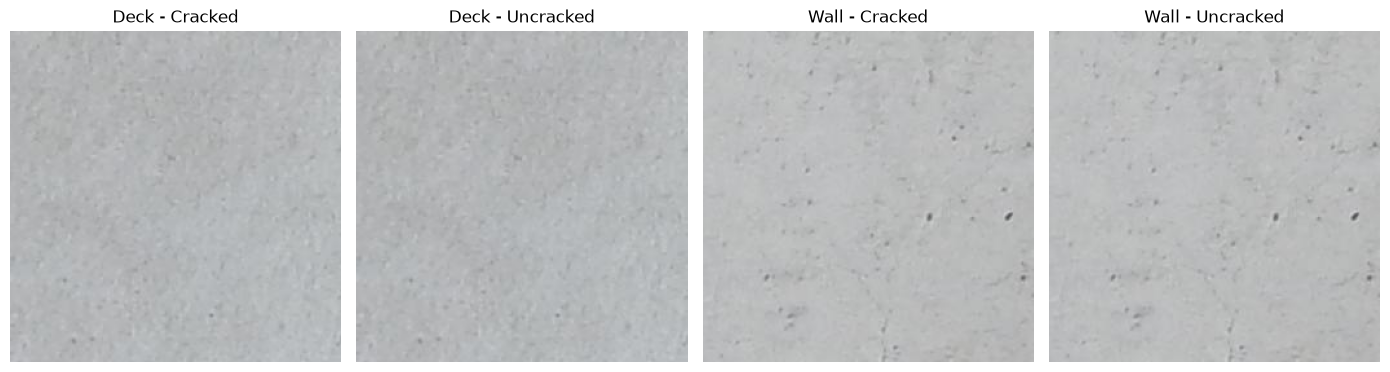

In [15]:
# Import Image to open the duplicate images
from PIL import Image

# Import matplotlib to display the images
import matplotlib.pyplot as plt

# Store the paths of the first cross-class duplicate pair
deck_cracked = DATA_DIR / "D" / "CD" / "7039-112.jpg"
deck_uncracked = DATA_DIR / "D" / "UD" / "7039-112_2.jpg"

# Store the paths of the second cross-class duplicate pair
wall_cracked = DATA_DIR / "W" / "CW" / "7074-105.jpg"
wall_uncracked = DATA_DIR / "W" / "UW" / "7074-105_2.jpg"

# Create a figure with four image positions
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

# Store each image path and its class label
image_pairs = [
    (deck_cracked, "Deck - Cracked"),
    (deck_uncracked, "Deck - Uncracked"),
    (wall_cracked, "Wall - Cracked"),
    (wall_uncracked, "Wall - Uncracked")
]

# Display each image with its assigned label
for ax, (image_path, title) in zip(axes, image_pairs):
    # Open the image
    img = Image.open(image_path)

    # Display the image
    ax.imshow(img)

    # Add the class label above the image
    ax.set_title(title)

    # Hide the axis markings
    ax.axis("off")

# Adjust the layout
plt.tight_layout()

# Display the images
plt.show()

## 8. Brightness and Contrast Distribution

This section examines the distribution of image brightness and contrast across the six dataset classes. Histograms are used to understand the variation in these image characteristics rather than relying only on average values.

In [16]:
# Import Path to work with folder locations
from pathlib import Path

# Set the location of the dataset
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Create a dictionary containing the six dataset classes
class_folders = {
    "Cracked Decks (CD)": DATA_DIR / "D" / "CD",
    "Uncracked Decks (UD)": DATA_DIR / "D" / "UD",
    "Cracked Pavements (CP)": DATA_DIR / "P" / "CP",
    "Uncracked Pavements (UP)": DATA_DIR / "P" / "UP",
    "Cracked Walls (CW)": DATA_DIR / "W" / "CW",
    "Uncracked Walls (UW)": DATA_DIR / "W" / "UW"
}

# Check that every class folder exists
for class_name, folder_path in class_folders.items():
    print(class_name, ":", folder_path.exists())

Cracked Decks (CD) : True
Uncracked Decks (UD) : True
Cracked Pavements (CP) : True
Uncracked Pavements (UP) : True
Cracked Walls (CW) : True
Uncracked Walls (UW) : True


In [17]:
# Import the required libraries
import numpy as np
import pandas as pd
import random
from PIL import Image

# Store the brightness and contrast measurements
image_stats = []

# Select 100 images from each class
sample_size = 100

# Set a random seed so the sample is reproducible
random.seed(42)

# Process each of the six image classes
for class_name, folder_path in class_folders.items():

    # Get all JPG images in the current class folder
    image_paths = list(folder_path.glob("*.jpg"))

    # Randomly select up to 100 images
    selected_images = random.sample(image_paths, min(sample_size, len(image_paths)))

    # Calculate brightness and contrast for each selected image
    for image_path in selected_images:

        # Open the image and convert it to grayscale
        img = Image.open(image_path).convert("L")

        # Convert the image pixels into a NumPy array
        pixels = np.array(img)

        # Calculate average brightness
        brightness = np.mean(pixels)

        # Calculate image contrast using standard deviation
        contrast = np.std(pixels)

        # Save the measurements and class name
        image_stats.append({
            "Class": class_name,
            "Brightness": brightness,
            "Contrast": contrast
        })

# Convert the measurements into a pandas DataFrame
image_stats_df = pd.DataFrame(image_stats)

# Display the first five rows
display(image_stats_df.head())

# Display the total number of images analysed
print("Images analysed:", len(image_stats_df))

,Class,Brightness,Contrast
0,Cracked Decks (CD),177.988937,7.377539
1,Cracked Decks (CD),176.361450,11.530525
2,Cracked Decks (CD),180.454834,12.823967
3,Cracked Decks (CD),182.110519,10.773874
4,Cracked Decks (CD),185.666870,6.163685


Images analysed: 600


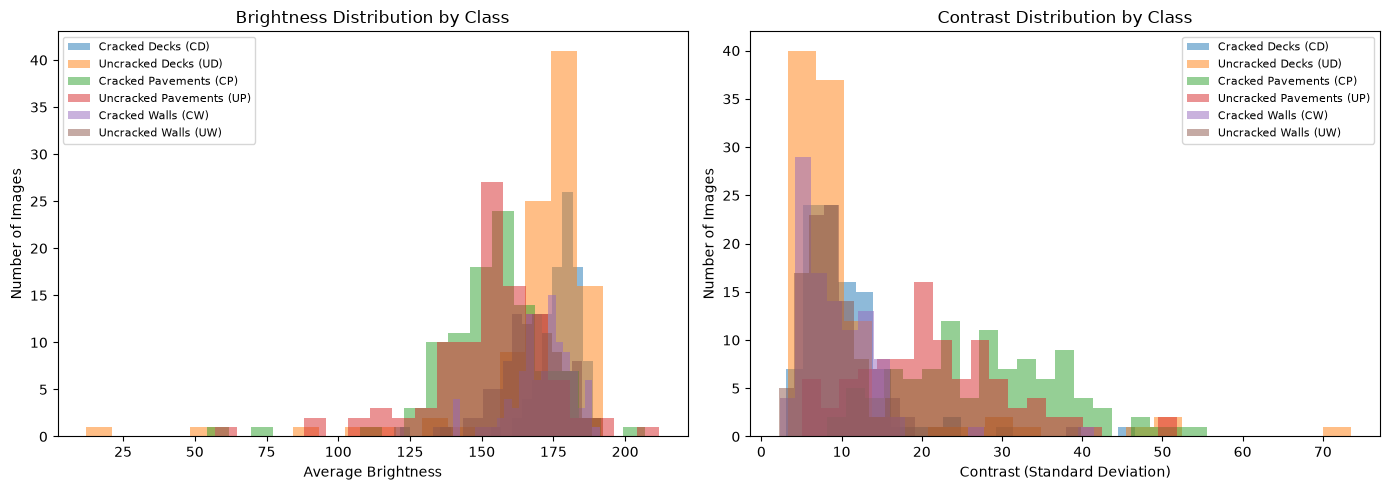

In [18]:
# Create a figure with two charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot brightness distributions for each class
for class_name in image_stats_df["Class"].unique():
    class_data = image_stats_df[image_stats_df["Class"] == class_name]
    axes[0].hist(class_data["Brightness"], bins=20, alpha=0.5, label=class_name)

# Add the brightness chart labels
axes[0].set_title("Brightness Distribution by Class")
axes[0].set_xlabel("Average Brightness")
axes[0].set_ylabel("Number of Images")
axes[0].legend(fontsize=8)

# Plot contrast distributions for each class
for class_name in image_stats_df["Class"].unique():
    class_data = image_stats_df[image_stats_df["Class"] == class_name]
    axes[1].hist(class_data["Contrast"], bins=20, alpha=0.5, label=class_name)

# Add the contrast chart labels
axes[1].set_title("Contrast Distribution by Class")
axes[1].set_xlabel("Contrast (Standard Deviation)")
axes[1].set_ylabel("Number of Images")
axes[1].legend(fontsize=8)

# Adjust the spacing between the charts
plt.tight_layout()

# Display both charts
plt.show()

In [1]:
usable_df = df[
    (df["is_valid"] == True) &
    (df["label"].isin(["Cracked", "Uncracked"])) &
    (df["surface_type"] != "Unknown")
].copy()

# Preserve one entry per exact file path.
usable_df = usable_df.drop_duplicates(subset=["path"])

print(f"Original image count: {len(df):,}")
print(f"Usable labeled images: {len(usable_df):,}")
print(f"Excluded from manifest: {len(df) - len(usable_df):,}")

print("\nFinal class distribution:")
display(usable_df["label"].value_counts().to_frame("count"))

print("\nFinal surface-type distribution:")
display(
    pd.crosstab(
        usable_df["surface_type"],
        usable_df["label"],
        margins=True
    )
)

NameError: name 'df' is not defined